In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#!pip install pyreadstat -q
!pip install pygam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 2.6 MB/s eta 0:00:00


#GAM PRE-PROCESSING

In [ ]:
#Imports and folders
import os
import glob
import numpy as np
import pandas as pd

from pathlib import Path

pd.set_option("display.max_columns", 200)

#Main DHS folder
BASE_FOLDER = "/content/drive/MyDrive/Hons_dataset/DHS Surveys"

#Folder containing IR DTA files
IR_FOLDER = os.path.join(BASE_FOLDER, "Individual Recodes")

#Folder containing BRDTA files
BR_FOLDER = os.path.join(BASE_FOLDER, "Birth Recodes")

print("BASE FOLDER:", BASE_FOLDER)
print("IR FOLDER:", IR_FOLDER)
print("BR FOLDER:", BR_FOLDER)

print("\nIR folder exists:", os.path.exists(IR_FOLDER))
print("BR folder exists:", os.path.exists(BR_FOLDER))

BASE FOLDER: /content/drive/MyDrive/Hons_dataset/DHS Surveys
IR FOLDER: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes
BR FOLDER: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes

IR folder exists: True
BR folder exists: True


In [ ]:
#Finding all IR and BR DTA files

ir_files = sorted(
    glob.glob(os.path.join(IR_FOLDER, "**", "*.DTA"), recursive=True)
    + glob.glob(os.path.join(IR_FOLDER, "**", "*.dta"), recursive=True)
)

br_files = sorted(
    glob.glob(os.path.join(BR_FOLDER, "**", "*.DTA"), recursive=True)
    + glob.glob(os.path.join(BR_FOLDER, "**", "*.dta"), recursive=True)
)

print("INDIVIDUAL RECODE FILES")
for f in ir_files:
    print(f)
print("\nTotal IR files:", len(ir_files))

print("\nBIRTH RECODE FILES")
for f in br_files:
    print(f)
print("\nTotal BR files:", len(br_files))

INDIVIDUAL RECODE FILES
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Burundi (2016)/BUIR71FL.DTA
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Ethiopia (2024)/ETIR8AFL.dta
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Kenya (2022)/KEIR8CFL.DTA
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Nigeria (2024)/NGIR8BFL.dta
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/South Africa (2016)/ZAIR71FL.DTA

Total IR files: 5

BIRTH RECODE FILES
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Burundi (2016) BR/BUBR71FL.DTA
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Ethiopia (2024) BR/ETBR8AFL.dta
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Kenya (2022) BR/KEBR8CFL.DTA
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Nigeria (2024) BR/NGBR8BFL.dta
/content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/South Africa (2016) BR/ZA

In [ ]:
#Reading DTA files

def read_dta(path):
    df = pd.read_stata(
        path,
        convert_categoricals=False
    )

    df.columns = (
        df.columns
        .astype(str)
        .str.upper()
    )

    return df


def find_file(files, country):
    matches = [
        f for f in files
        if country.lower() in f.lower()
    ]

    if len(matches) == 0:
        return None

    if len(matches) > 1:
        print("WARNING: multiple files found for",country)
        for f in matches:
            print("   ", f)

    return matches[0]

SURVEYS = {"BURUNDI (2016)": {"country": "BURUNDI","year": 2016},"ETHIOPIA (2024)": {"country": "ETHIOPIA","year": 2024},"KENYA (2022)": {"country": "KENYA","year": 2022},
           "NIGERIA (2024)": {"country": "NIGERIA","year": 2024},"SOUTH AFRICA (2016)": {"country": "SOUTH AFRICA","year": 2016} }
survey_data = {}

for survey_name, info in SURVEYS.items():

    country = info["country"]



    print(survey_name)


    ir_path = find_file(ir_files, country)
    br_path = find_file(br_files, country)

    print("IR:", ir_path)
    print("BR:", br_path)

    if ir_path is None or br_path is None:
        print("ERROR: Could not find both files.")
        continue

    ir = read_dta(ir_path)
    br = read_dta(br_path)

    survey_data[survey_name] = {
        "IR": ir,
        "BR": br
    }

    print("IR shape:", ir.shape)
    print("BR shape:", br.shape)

BURUNDI (2016)
IR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Burundi (2016)/BUIR71FL.DTA
BR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Burundi (2016) BR/BUBR71FL.DTA
IR shape: (17269, 5022)
BR shape: (45419, 1136)
ETHIOPIA (2024)
IR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Ethiopia (2024)/ETIR8AFL.dta
BR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Ethiopia (2024) BR/ETBR8AFL.dta
IR shape: (21395, 6648)
BR shape: (52434, 1307)
KENYA (2022)
IR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Kenya (2022)/KEIR8CFL.DTA
BR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Kenya (2022) BR/KEBR8CFL.DTA
IR shape: (32156, 5925)
BR shape: (77381, 1319)
NIGERIA (2024)
IR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Individual Recodes/Nigeria (2024)/NGIR8BFL.dta
BR: /content/drive/MyDrive/Hons_dataset/DHS Surveys/Birth Recodes/Nigeria (2024) BR/NGBR8BFL.dta
IR shape: (3905

In [ ]:
#Checking requird variables
REQUIRED_IR = [
    #Maternal identification
    "CASEID",
    "V012",      #Mother's age
    "V437",      #Mother's weight
    "V438",      #Mother's height
    "V445",      #Mother's BMI
    "V404",      #Currently breastfeeding
    "V213",      #Current pregnancy status
    "V218",      #Pregnancy status/detail
    "V453",      #Haemoglobin level
    "V456",      #Adjusted haemoglobin level
    "V457"       #Anaemia status
]


REQUIRED_BR = [
    #Identification for BR
    "CASEID",
    "BIDX",
    "B19",
    "B8",
    "M4",
    "M5"
]

#Checking each country
for survey_name, data in survey_data.items():
    ir = data["IR"]
    br = data["BR"]
    print(survey_name)

    #IR
    print("\nINDIVIDUAL RECODE")
    for var in REQUIRED_IR:
        if var in ir.columns:
            print(
                f"{var:<8} present | "
                f"non-missing: {ir[var].notna().sum():,} | "
                f"dtype: {ir[var].dtype}")
        else:

            print(f"{var:<8} NOT FOUND")

    #BR
    print("\nBIRTH RECODE")
    for var in REQUIRED_BR:
        if var in br.columns:

            print(
                f"{var:<8} present | "
                f"non-missing: {br[var].notna().sum():,} | "
                f"dtype: {br[var].dtype}")
        else:
            print(f"{var:<8} NOT FOUND")

BURUNDI (2016)

INDIVIDUAL RECODE
CASEID   present | non-missing: 17,269 | dtype: object
V012     present | non-missing: 17,269 | dtype: int8
V437     present | non-missing: 8,664 | dtype: float64
V438     present | non-missing: 8,664 | dtype: float64
V445     present | non-missing: 8,581 | dtype: float64
V404     present | non-missing: 17,269 | dtype: int8
V213     present | non-missing: 17,269 | dtype: int8
V218     present | non-missing: 17,269 | dtype: int8
V453     present | non-missing: 8,664 | dtype: float64
V456     present | non-missing: 8,539 | dtype: float64
V457     present | non-missing: 8,539 | dtype: float64

BIRTH RECODE
CASEID   present | non-missing: 45,419 | dtype: object
BIDX     present | non-missing: 45,419 | dtype: int8
B19      present | non-missing: 45,419 | dtype: int16
B8       present | non-missing: 40,305 | dtype: float64
M4       present | non-missing: 13,192 | dtype: float64
M5       present | non-missing: 13,192 | dtype: float64
ETHIOPIA (2024)

INDIVIDU

In [ ]:
#Building maternal and youngest child dataset
import pandas as pd
import numpy as np

#Variables we need
IR_KEEP = [
    "CASEID",
    "V012",   # mother's age
    "V437",   # weight
    "V438",   # height
    "V445",   # BMI
    "V404",   # currently breastfeeding
    "V213",   # currently pregnant
    "V218",   # pregnancy-related variable
    "V453",   # haemoglobin
    "V456",   # adjusted haemoglobin
    "V457"    # anaemia
]

BR_KEEP = [
    "CASEID",
    "BIDX",
    "B19"
]

country_datasets = {}

#Processing each country
for survey_name, data in survey_data.items():
    print(f"PROCESSING: {survey_name}")
    ir = data["IR"]
    br = data["BR"]


    #Checking required IR variables
    missing_ir = [
        var for var in IR_KEEP
        if var not in ir.columns
    ]

    if missing_ir:

        print("WARNING - Missing IR variables:")
        print(missing_ir)

        #Keeping only variables that actually exist
        ir_keep_actual = [
            var for var in IR_KEEP
            if var in ir.columns
        ]

    else:
        ir_keep_actual = IR_KEEP


    #Selecting only required IR columns
    maternal = ir[ir_keep_actual].copy()

    #Selecting only required BR columns
    missing_br = [
        var for var in BR_KEEP
        if var not in br.columns
    ]

    if missing_br:

        print("WARNING - Missing BR variables:")
        print(missing_br)

        br_keep_actual = [
            var for var in BR_KEEP
            if var in br.columns
        ]

    else:

        br_keep_actual = BR_KEEP

    births = br[br_keep_actual].copy()


    #Keeping youngest child only

    if "BIDX" in births.columns:

        births = births[
            births["BIDX"] == 1
        ].copy()


    #Removeing duplicate CASEIDs in BR
    births = births.drop_duplicates(
        subset="CASEID",
        keep="first"
    )


    #Renaming B19
    if "B19" in births.columns:

        births = births.rename(
            columns={
                "B19": "CHILD_AGE_MONTHS"
            }
        )


    #Merging maternal data with youngest child
    merged = maternal.merge(
        births,
        on="CASEID",
        how="left",
        suffixes=("", "_BR")
    )


    #Currently breastfeeding
    if "V404" in merged.columns:
        merged["CURRENTLY_BREASTFEEDING"] = (
            merged["V404"]
            .map({
                1: 1,
                0: 0
            })
        )

    else:
        merged["CURRENTLY_BREASTFEEDING"] = np.nan


    #Lactation stage
    def classify_lactation(row):
        breastfeeding = row["CURRENTLY_BREASTFEEDING"]
        child_age = row["CHILD_AGE_MONTHS"]

        if breastfeeding == 0:
            return "Not breastfeeding"

        if pd.isna(breastfeeding):
            return "Unknown"

        if breastfeeding == 1:

            if pd.isna(child_age):
                return "Unknown"

            if child_age <= 6:
                return "Early lactation (0-6 months)"

            elif child_age <= 12:
                return "Mid lactation (7-12 months)"

            else:
                return "Late lactation (>12 months)"

        return "Unknown"

    merged["LACTATION_STAGE"] = merged.apply(
        classify_lactation,
        axis=1
    )

    #Adding country
    merged["COUNTRY"] = survey_name

    #Storing
    country_datasets[survey_name] = merged

    #Output check
    print("Maternal rows:", len(maternal))
    print("Youngest child records:", len(births))
    print("Merged rows:", len(merged))
    print("\nBreastfeeding:")
    print(merged["CURRENTLY_BREASTFEEDING"].value_counts(dropna=False))
    print("\nLactation stage:")
    print(merged["LACTATION_STAGE"].value_counts(dropna=False))


PROCESSING: BURUNDI (2016)
Maternal rows: 17269
Youngest child records: 11081
Merged rows: 17269

Breastfeeding:
CURRENTLY_BREASTFEEDING
0    11548
1     5721
Name: count, dtype: int64

Lactation stage:
LACTATION_STAGE
Not breastfeeding               11548
Late lactation (>12 months)      2958
Early lactation (0-6 months)     1410
Mid lactation (7-12 months)      1353
Name: count, dtype: int64
PROCESSING: ETHIOPIA (2024)
Maternal rows: 21395
Youngest child records: 13830
Merged rows: 21395

Breastfeeding:
CURRENTLY_BREASTFEEDING
0    16577
1     4818
Name: count, dtype: int64

Lactation stage:
LACTATION_STAGE
Not breastfeeding               16577
Late lactation (>12 months)      2219
Early lactation (0-6 months)     1455
Mid lactation (7-12 months)      1144
Name: count, dtype: int64
PROCESSING: KENYA (2022)
Maternal rows: 32156
Youngest child records: 23343
Merged rows: 32156

Breastfeeding:
CURRENTLY_BREASTFEEDING
0    25459
1     6697
Name: count, dtype: int64

Lactation stage:
LACT

In [ ]:
#Creating a clean standardised nutrition dataset
import pandas as pd
import numpy as np

clean_datasets = {}
for survey_name, df in country_datasets.items():
    print(f"PROCESSING: {survey_name}")

    #Starting with an empty dataframe
    clean = pd.DataFrame(index=df.index)

    #Identification
    clean["CASEID"] = df["CASEID"]
    clean["COUNTRY"] = survey_name

    #Demographics
    #Mother's age
    clean["AGE"] = df["V012"]
    #Number of living children
    clean["NUMBER_LIVING_CHILDREN"] = df["V218"]

    #Anthropometry
    #Weight
    clean["WEIGHT"] = df["V437"]
    #Height
    clean["HEIGHT"] = df["V438"]
    #BMI
    clean["BMI"] = df["V445"] / 100

    #Breastfeeding
    clean["CURRENTLY_BREASTFEEDING"] = (
        df["CURRENTLY_BREASTFEEDING"]
    )

    #Pregnancy
    clean["CURRENTLY_PREGNANT"] = df["V213"]

    #Youngest child
    clean["CHILD_AGE_MONTHS"] = df["CHILD_AGE_MONTHS"]

    #Lactation stage
    clean["LACTATION_STAGE"] = df["LACTATION_STAGE"]

    #Anemia
    if "V457" in df.columns:

        clean["ANAEMIA_RAW"] = df["V457"]

    else:

        clean["ANAEMIA_RAW"] = np.nan

    #Removing completely empty columns
    clean = clean.dropna(
        axis=1,
        how="all"
    )

    #Storing country dataset
    clean_datasets[survey_name] = clean

    #Displsying basic info
    print("Rows:", len(clean))
    print("Columns:", len(clean.columns))

    print("\nColumns:")
    print(list(clean.columns))

    print("\nMissing values:")
    print(clean.isna().sum())


#Combining all countries
final_preprocessing_df = pd.concat(
    clean_datasets.values(),
    ignore_index=True
)



print("FINAL PREPROCESSING DATASET")
print("Rows:", len(final_preprocessing_df))
print("Columns:", len(final_preprocessing_df.columns))
print("\nColumns:")
print(list(final_preprocessing_df.columns))
print("\nCountry counts:")
print(final_preprocessing_df["COUNTRY"].value_counts())
print("\nLactation stage:")
print(final_preprocessing_df["LACTATION_STAGE"].value_counts(dropna=False))


PROCESSING: BURUNDI (2016)
Rows: 17269
Columns: 12

Columns:
['CASEID', 'COUNTRY', 'AGE', 'NUMBER_LIVING_CHILDREN', 'WEIGHT', 'HEIGHT', 'BMI', 'CURRENTLY_BREASTFEEDING', 'CURRENTLY_PREGNANT', 'CHILD_AGE_MONTHS', 'LACTATION_STAGE', 'ANAEMIA_RAW']

Missing values:
CASEID                        0
COUNTRY                       0
AGE                           0
NUMBER_LIVING_CHILDREN        0
WEIGHT                     8605
HEIGHT                     8605
BMI                        8688
CURRENTLY_BREASTFEEDING       0
CURRENTLY_PREGNANT            0
CHILD_AGE_MONTHS           6188
LACTATION_STAGE               0
ANAEMIA_RAW                8730
dtype: int64
PROCESSING: ETHIOPIA (2024)
Rows: 21395
Columns: 11

Columns:
['CASEID', 'COUNTRY', 'AGE', 'NUMBER_LIVING_CHILDREN', 'WEIGHT', 'HEIGHT', 'BMI', 'CURRENTLY_BREASTFEEDING', 'CURRENTLY_PREGNANT', 'CHILD_AGE_MONTHS', 'LACTATION_STAGE']

Missing values:
CASEID                         0
COUNTRY                        0
AGE                      

In [ ]:
#Final GAM ready input pre-processing
import pandas as pd
import numpy as np

#Building breastfeeding datasets
final_country_datasets = {}

for country, df in clean_datasets.items():
    final = df.copy()

    #Keeping currently breastfeeding women only
    if "CURRENTLY_BREASTFEEDING" not in final.columns:
        raise ValueError(
            f"{country} does not contain CURRENTLY_BREASTFEEDING."
        )

    final["CURRENTLY_BREASTFEEDING"] = pd.to_numeric(
        final["CURRENTLY_BREASTFEEDING"],
        errors="coerce"
    )

    final = final[
        final["CURRENTLY_BREASTFEEDING"] == 1
    ].copy()

    final_country_datasets[country] = final

    print(f"{country}: {len(final)} breastfeeding women retained")

#Standardising numerical var
numeric_variables = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CHILD_AGE_MONTHS",
    "CURRENTLY_PREGNANT"
]

for country, df in final_country_datasets.items():
    for variable in numeric_variables:
        if variable in df.columns:
            df[variable] = pd.to_numeric(
                df[variable],
                errors="coerce")
        else:

            print(f"WARNING: {country} does not contain {variable}")

#Coverting DHS anthropomentric measurements
for country, df in final_country_datasets.items():

    #DHS respondent weight is represented in tenths of kilograms
    if "WEIGHT" in df.columns:
        df["WEIGHT"] = df["WEIGHT"] / 10

    #DHS respondent height is represented in tenths of centimetres
    if "HEIGHT" in df.columns:
        df["HEIGHT"] = df["HEIGHT"] / 10

    print(country)
    if "WEIGHT" in df.columns:
        print("Weight sample:")
        print(df["WEIGHT"].head().to_list())

    if "HEIGHT" in df.columns:
        print("Height sample:")
        print(df["HEIGHT"].head().to_list())



#Removing unnessary variables
variables_to_remove = [
    "BMI",
    "CURRENTLY_BREASTFEEDING",
    "ANAEMIA_RAW",
    "ANAEMIA_STATUS"
]

for country, df in final_country_datasets.items():
    existing = [
        variable
        for variable in variables_to_remove
        if variable in df.columns
    ]
    if existing:
        df.drop(
            columns=existing,
            inplace=True
        )
    print(country,"| Removed:",existing)



#Validating and cleaning numeric variables
for country, df in final_country_datasets.items():
    if "AGE" in df.columns:

        df.loc[
            (df["AGE"] < 15) |
            (df["AGE"] > 49),
            "AGE"
        ] = np.nan

    if "NUMBER_LIVING_CHILDREN" in df.columns:

        df.loc[
            df["NUMBER_LIVING_CHILDREN"] < 0,
            "NUMBER_LIVING_CHILDREN"
        ] = np.nan

    if "WEIGHT" in df.columns:

        df.loc[
            (df["WEIGHT"] <= 0) |
            (df["WEIGHT"] > 250),
            "WEIGHT"
        ] = np.nan

    if "HEIGHT" in df.columns:

        df.loc[
            (df["HEIGHT"] <= 0) |
            (df["HEIGHT"] > 250),
            "HEIGHT"
        ] = np.nan

    if "CHILD_AGE_MONTHS" in df.columns:

        df.loc[
            (df["CHILD_AGE_MONTHS"] < 0) |
            (df["CHILD_AGE_MONTHS"] > 59),
            "CHILD_AGE_MONTHS"
        ] = np.nan

#Standardizing pregnancy status
for country, df in final_country_datasets.items():
    if "CURRENTLY_PREGNANT" not in df.columns:
        raise ValueError(
            f"{country} is missing CURRENTLY_PREGNANT."
        )

    df["CURRENTLY_PREGNANT"] = pd.to_numeric(
        df["CURRENTLY_PREGNANT"],
        errors="coerce"
    )

    df.loc[
        ~df["CURRENTLY_PREGNANT"].isin([0, 1]),
        "CURRENTLY_PREGNANT"
    ] = np.nan

    print(country)
    print(df["CURRENTLY_PREGNANT"].value_counts(dropna=False))



#Creating lact stage
for country, df in final_country_datasets.items():
    if "CHILD_AGE_MONTHS" not in df.columns:
        raise ValueError(
            f"{country} is missing CHILD_AGE_MONTHS."
        )
    df["LACTATION_STAGE"] = pd.Series(
        pd.NA,
        index=df.index,
        dtype="string"
    )

    #0-6 months
    df.loc[
        df["CHILD_AGE_MONTHS"].between(0, 6),
        "LACTATION_STAGE"
    ] = "Early lactation"

    #7-12 months
    df.loc[
        df["CHILD_AGE_MONTHS"].between(7, 12),
        "LACTATION_STAGE"
    ] = "Mid lactation"

    #>12 months
    df.loc[
        df["CHILD_AGE_MONTHS"] > 12,
        "LACTATION_STAGE"
    ] = "Late lactation"


    print(country)
    print(df["LACTATION_STAGE"].value_counts(dropna=False))



#Creating country identifier
for country, df in final_country_datasets.items():

    df["COUNTRY"] = str(country)

    df["COUNTRY"] = (
        df["COUNTRY"]
        .astype("string")
    )

    print("", country)

#Validating variables
required_variables = [
    "CASEID",
    "COUNTRY",
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE"
]

for country, df in final_country_datasets.items():

    missing_variables = [
        variable
        for variable in required_variables
        if variable not in df.columns
    ]

    if missing_variables:

        raise ValueError(
            f"{country} is missing required variables: "
            f"{missing_variables}"
        )

    print(
        f"{country}: all required variables present "
    )



#Removing rows with missing GAM inputs
predictor_variables = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE",
    "COUNTRY"
]

for country, df in final_country_datasets.items():

    before = len(df)

    missing_counts = (
        df[predictor_variables]
        .isna()
        .sum()
    )

    df.dropna(
        subset=predictor_variables,
        inplace=True
    )

    after = len(df)


    print(country)
    print("Rows before:", before)
    print("Rows removed:", before - after)
    print("Rows remaining:", after)

    print("Missing values before removal:")
    print(missing_counts)



#Selecting final variables
final_columns = [
    "CASEID",
    "COUNTRY",
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE"
]

for country, df in final_country_datasets.items():

    final_country_datasets[country] = (
        df[final_columns]
        .copy()
    )

#Combining countries
gam_ready_df = pd.concat(
    final_country_datasets.values(),
    ignore_index=True
)

print("Combined rows:",len(gam_ready_df))



#Country aware ID
gam_ready_df["PARTICIPANT_ID"] = (
    gam_ready_df["COUNTRY"].astype("string")
    + "_"
    + gam_ready_df["CASEID"].astype("string")
)

duplicate_country_caseid = (
    gam_ready_df
    .duplicated(
        subset=["COUNTRY", "CASEID"]
    )
    .sum()
)

duplicate_participant_ids = (
    gam_ready_df["PARTICIPANT_ID"]
    .duplicated()
    .sum()
)

print(
    "Duplicate COUNTRY + CASEID:",
    duplicate_country_caseid
)

print(
    "Duplicate PARTICIPANT_ID:",
    duplicate_participant_ids
)

if duplicate_country_caseid > 0:


    print("WARNING:")
    print(
        "Some COUNTRY + CASEID combinations occur more than once."
    )
    print(
        "These must be investigated before modelling."
    )



#Setting data types
numeric_predictors = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS"
]

for variable in numeric_predictors:
    gam_ready_df[variable] = pd.to_numeric(
        gam_ready_df[variable],
        errors="coerce"
    )

categorical_predictors = [
    "COUNTRY",
    "LACTATION_STAGE"
]

for variable in categorical_predictors:

    gam_ready_df[variable] = (
        gam_ready_df[variable]
        .astype("category")
    )



#Final GAM input Dataset
gam_input_variables = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE",
    "COUNTRY"
]

gam_input_df = gam_ready_df[
    [
        "PARTICIPANT_ID",
        "CASEID",
        "COUNTRY",
        "AGE",
        "NUMBER_LIVING_CHILDREN",
        "WEIGHT",
        "HEIGHT",
        "CURRENTLY_PREGNANT",
        "CHILD_AGE_MONTHS",
        "LACTATION_STAGE"
    ]
].copy()



#Final missing value check
print("Final missing value check")
missing_summary = (
    gam_input_df[gam_input_variables]
    .isna()
    .sum()
)

print(
    missing_summary
)

if missing_summary.sum() != 0:

    raise ValueError(
        "Missing values remain in GAM predictors."
    )

print(
    " No missing GAM predictor values"
)

#Range validation
print("Range validation")
range_rules = {
    "AGE": (15, 49),
    "NUMBER_LIVING_CHILDREN": (0, None),
    "WEIGHT": (0, 250),
    "HEIGHT": (0, 250),
    "CHILD_AGE_MONTHS": (0, 59)
}

range_errors = {}

for variable, (minimum, maximum) in range_rules.items():

    invalid_mask = pd.Series(
        False,
        index=gam_input_df.index
    )

    if minimum is not None:

        invalid_mask |= (
            gam_input_df[variable] < minimum
        )

    if maximum is not None:

        invalid_mask |= (
            gam_input_df[variable] > maximum
        )

    count = invalid_mask.sum()

    range_errors[variable] = count

    print(
        variable,
        "| invalid:",
        count,
        "| min:",
        gam_input_df[variable].min(),
        "| max:",
        gam_input_df[variable].max()
    )

if sum(range_errors.values()) != 0:

    raise ValueError(
        "Invalid values remain after preprocessing."
    )

print(
    " All numeric variables pass range validation"
)

#Categorical validation
print("Categorical validation")
valid_lactation_stages = [
    "Early lactation",
    "Mid lactation",
    "Late lactation"
]

invalid_lactation = (
    ~gam_input_df["LACTATION_STAGE"]
    .isin(valid_lactation_stages)
).sum()

invalid_pregnancy = (
    ~gam_input_df["CURRENTLY_PREGNANT"]
    .isin([0, 1])
).sum()

invalid_country = (
    gam_input_df["COUNTRY"].isna()
).sum()

print(
    "Invalid lactation stages:",
    invalid_lactation
)

print(
    "Invalid pregnancy values:",
    invalid_pregnancy
)

print(
    "Missing country:",
    invalid_country
)

if (
    invalid_lactation
    + invalid_pregnancy
    + invalid_country
) != 0:

    raise ValueError(
        "Categorical validation failed."
    )

print(
    " Categorical variables pass validation"
)



#Country distribution
print("Country distribution")
country_distribution = (
    gam_input_df["COUNTRY"]
    .value_counts()
)

country_percentages = (
    gam_input_df["COUNTRY"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

country_summary = pd.DataFrame({
    "COUNT": country_distribution,
    "PERCENT": country_percentages
})

print(
    country_summary
)


print(
    "Country imbalance is retained and will be considered during "
    "model evaluation/validation rather than corrected by deleting observations."
)



#Lact stage dist
print("Lactation stage distribution")
stage_distribution = (
    gam_input_df["LACTATION_STAGE"]
    .value_counts()
)

stage_percentages = (
    gam_input_df["LACTATION_STAGE"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

stage_summary = pd.DataFrame({
    "COUNT": stage_distribution,
    "PERCENT": stage_percentages
})

print(
    stage_summary
)



#Descriptive stat
print("Descriptive statistics")
numeric_gam_variables = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CHILD_AGE_MONTHS"
]

print(
    gam_input_df[numeric_gam_variables]
    .describe()
    .T
)

#Distribution by lact stage
print("Distribution by lactation stage")
for variable in numeric_gam_variables:


    print(f"--- {variable} ---")

    print(
        gam_input_df
        .groupby(
            "LACTATION_STAGE",
            observed=True
        )[variable]
        .describe()
    )

#Country level summary
print("Country level summary")
for variable in [
    "AGE",
    "WEIGHT",
    "HEIGHT",
    "CHILD_AGE_MONTHS"
]:
    print(f"--- {variable} by country ---")

    print(
        gam_input_df
        .groupby(
            "COUNTRY",
            observed=True
        )[variable]
        .agg([
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ])
    )



#Outlier identification
print("Outlier identification")
outlier_summary = []

for variable in numeric_gam_variables:

    Q1 = gam_input_df[variable].quantile(0.25)
    Q3 = gam_input_df[variable].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (gam_input_df[variable] < lower_bound) |
        (gam_input_df[variable] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_percentage = (
        outlier_count / len(gam_input_df) * 100
    )

    outlier_summary.append({
        "VARIABLE": variable,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "LOWER_BOUND": lower_bound,
        "UPPER_BOUND": upper_bound,
        "OUTLIER_COUNT": outlier_count,
        "OUTLIER_PERCENT": round(
            outlier_percentage,
            2
        )
    })

outlier_summary_df = pd.DataFrame(
    outlier_summary
)

print(
    outlier_summary_df.to_string(
        index=False
    )
)


print(
    " IQR outliers identified for review only."
)
print(
    " No observations were removed solely because they were statistical outliers."
)

#Extreme value inspection
print("Extreme value inspection")

for variable in numeric_gam_variables:
    print(f"--- {variable} ---")

    print(
        "Lowest 10:",
        gam_input_df[variable]
        .nsmallest(10)
        .to_list()
    )

    print(
        "Highest 10:",
        gam_input_df[variable]
        .nlargest(10)
        .to_list()
    )



#Correlation bet numeric var

print("Correlation matrix")
correlation_matrix = (
    gam_input_df[numeric_gam_variables]
    .corr()
)

print(
    correlation_matrix.round(3)
)

#Duplicate check
print("Duplicate participant check")

duplicate_country_caseid = (
    gam_input_df
    .duplicated(
        subset=["COUNTRY", "CASEID"]
    )
    .sum()
)

duplicate_participant_id = (
    gam_input_df["PARTICIPANT_ID"]
    .duplicated()
    .sum()
)

print(
    "Duplicate COUNTRY + CASEID:",
    duplicate_country_caseid
)

print(
    "Duplicate PARTICIPANT_ID:",
    duplicate_participant_id
)

if duplicate_country_caseid > 0:


    print(
        "WARNING: duplicate participant records remain."
    )

else:

    print(
        " COUNTRY + CASEID is unique"
    )



#final data types
print("Final data types")


print(
    gam_input_df.dtypes
)



#GAM input summary
print("Input summary")
print("Dataset:", "gam_input_df")
print("Rows:",len(gam_input_df))
print("Columns:",len(gam_input_df.columns))
print("GAM predictors:")
for variable in gam_input_variables:

    print(
        "",
        variable,
        "| dtype:",
        gam_input_df[variable].dtype,
        "| missing:",
        gam_input_df[variable].isna().sum(),
        "| unique:",
        gam_input_df[variable].nunique()
    )



#Final validation
print("Final validation")
final_checks = {

    "Missing GAM predictors":
        gam_input_df[gam_input_variables]
        .isna()
        .sum()
        .sum(),

    "Negative AGE":
        (
            gam_input_df["AGE"] < 0
        ).sum(),

    "Negative NUMBER_LIVING_CHILDREN":
        (
            gam_input_df["NUMBER_LIVING_CHILDREN"] < 0
        ).sum(),

    "Invalid WEIGHT":
        (
            (gam_input_df["WEIGHT"] <= 0) |
            (gam_input_df["WEIGHT"] > 250)
        ).sum(),

    "Invalid HEIGHT":
        (
            (gam_input_df["HEIGHT"] <= 0) |
            (gam_input_df["HEIGHT"] > 250)
        ).sum(),

    "Invalid CHILD_AGE_MONTHS":
        (
            (gam_input_df["CHILD_AGE_MONTHS"] < 0) |
            (gam_input_df["CHILD_AGE_MONTHS"] > 59)
        ).sum(),

    "Invalid pregnancy values":
        (
            ~gam_input_df["CURRENTLY_PREGNANT"]
            .isin([0, 1])
        ).sum(),

    "Invalid lactation stages":
        (
            ~gam_input_df["LACTATION_STAGE"]
            .isin(valid_lactation_stages)
        ).sum(),

    "Missing country":
        gam_input_df["COUNTRY"]
        .isna()
        .sum(),

    "Duplicate COUNTRY + CASEID":
        gam_input_df
        .duplicated(
            subset=["COUNTRY", "CASEID"]
        )
        .sum()
}

for check, result in final_checks.items():

    print(
        f"{check}: {result}"
    )



#Final status
print("Final dataset object:")
print("gam_input_df")
print("Final rows:", len(gam_input_df))
print("Final columns:", len(gam_input_df.columns))
print("Final GAM predictors:")
for variable in gam_input_variables:
    print("", variable)

BURUNDI (2016): 5721 breastfeeding women retained
ETHIOPIA (2024): 4818 breastfeeding women retained
KENYA (2022): 6697 breastfeeding women retained
NIGERIA (2024): 7970 breastfeeding women retained
SOUTH AFRICA (2016): 729 breastfeeding women retained
BURUNDI (2016)
Weight sample:
[51.7, 45.8, 34.9, nan, 48.6]
Height sample:
[159.5, 160.5, 144.4, nan, 155.7]
ETHIOPIA (2024)
Weight sample:
[nan, 49.6, 62.1, 49.5, 49.7]
Height sample:
[nan, 156.0, 156.9, 155.9, 152.1]
KENYA (2022)
Weight sample:
[97.3, nan, 63.9, 57.5, 63.2]
Height sample:
[161.4, nan, 164.1, 157.1, 149.5]
NIGERIA (2024)
Weight sample:
[57.9, nan, 59.0, nan, nan]
Height sample:
[159.6, nan, 159.3, nan, nan]
SOUTH AFRICA (2016)
Weight sample:
[nan, 63.7, nan, 62.6, nan]
Height sample:
[nan, 154.3, nan, 156.5, nan]
BURUNDI (2016) | Removed: ['BMI', 'CURRENTLY_BREASTFEEDING', 'ANAEMIA_RAW']
ETHIOPIA (2024) | Removed: ['BMI', 'CURRENTLY_BREASTFEEDING']
KENYA (2022) | Removed: ['BMI', 'CURRENTLY_BREASTFEEDING']
NIGERIA (2024

In [ ]:
#GAM target defn & variation analysis
import pandas as pd
import os

#GAM target defn table
target_definitions = [

    {
        "NUTRIENT": "Energy",
        "UNIT": "kcal/day",
        "INPUT": "Age, BMI, lactation stage, pregnancy status, country",
        "TARGET_RELATIONSHIP": "Individual energy requirement based on maternal characteristics and lactation context",
        "FORMULA": "To be defined from validated energy requirement equations",
        "RULE": "Individualised requirement; not a fixed 2300 kcal/day target",
        "SOURCE": "Yu et al. (2018); Herrero et al. (2025); applicable validated guideline",
        "PRODUCES_VARIATION": "Individualized target"
    },

    {
        "NUTRIENT": "Protein",
        "UNIT": "g/day",
        "INPUT": "Maternal body size, lactation stage, age",
        "TARGET_RELATIONSHIP": "Protein requirement related to maternal body size and lactation",
        "FORMULA": "1.1 g/kg/day where valid body-weight information is available",
        "RULE": "Use body-weight-dependent requirement where supported; otherwise use validated lactation reference value",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Individualized target"
    },

    {
        "NUTRIENT": "Vitamin A",
        "UNIT": "µg RAE/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated lactation reference intake; do not invent unsupported individual variation",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin B1 (Thiamine)",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin B2 (Riboflavin)",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin B3 (Niacin)",
        "UNIT": "mg NE/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin B6",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Folate",
        "UNIT": "µg DFE/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake and verify DFE unit basis",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin B12",
        "UNIT": "µg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin C",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Vitamin D",
        "UNIT": "µg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Reference requirement during lactation",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake; avoid unsupported individual variation",
        "SOURCE": "Herrero et al. (2025); EFSA reference values",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Calcium",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Reference requirement during lactation",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake; approximately 1000 mg/day where supported",
        "SOURCE": "U_2018; EFSA 2024; WHO/FAO 2024; Herrero et al.",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Iron",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement influenced by bioavailability/reference framework",
        "FORMULA": "Use selected validated reference value after resolving source differences",
        "RULE": "Do not combine conflicting source values without justification",
        "SOURCE": "U_2018; EFSA 2024; WHO/FAO 2024; Herrero et al.",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Zinc",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation requirement affected by reference framework and bioavailability",
        "FORMULA": "Use validated reference value according to selected framework",
        "RULE": "Use one consistent reference framework",
        "SOURCE": "U_2018; EFSA 2024; WHO/FAO 2024; Herrero et al.",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Iodine",
        "UNIT": "µg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific reference requirement",
        "FORMULA": "Reference intake according to selected guideline",
        "RULE": "Use validated lactation reference value; extra variation only if supported",
        "SOURCE": "U_2018; EFSA 2024; WHO/FAO 2024; Herrero et al.",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Magnesium",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Reference requirement during lactation",
        "FORMULA": "Stage/group-specific reference value where supported",
        "RULE": "Use validated reference intake",
        "SOURCE": "U_2018; EFSA 2024; WHO/FAO 2024; Herrero et al.",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "Selenium",
        "UNIT": "µg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Reference requirement during lactation",
        "FORMULA": "Validated lactation reference value",
        "RULE": "Verify source value before generating target",
        "SOURCE": "U_2018; Herrero et al. (2024/2025 sources)",
        "PRODUCES_VARIATION": "Group-dependent target"
    },

    {
        "NUTRIENT": "EPA + DHA",
        "UNIT": "mg/day",
        "INPUT": "Lactation stage, age, country",
        "TARGET_RELATIONSHIP": "Lactation-specific omega-3 fatty-acid recommendation",
        "FORMULA": "Validated EPA + DHA reference/AI",
        "RULE": "Use one consistent reference recommendation",
        "SOURCE": "EFSA 2024; Herrero et al. (2025)",
        "PRODUCES_VARIATION": "Group-dependent target"
    }
]



#Creating dataframe
gam_target_definition_table = pd.DataFrame(target_definitions)

#Display
print("\n")
print("FINAL GAM TARGET-DEFINITION TABLE")
display(gam_target_definition_table)

#Target count
print("\n")
print("TARGET COUNT")
print(f"Number of candidate GAM targets: {len(gam_target_definition_table)}")

if len(gam_target_definition_table) == 18:
    print(" Exactly 18 candidate targets defined.")
else:
    print("Target count differs from expected 18.")



#Target by variation type
print("\n")
print("TARGET VARIATION CLASSIFICATION")

variation_summary = (
    gam_target_definition_table
    .groupby("PRODUCES_VARIATION")
    .size()
    .reset_index(name="COUNT")
)

display(variation_summary)

#List targets in each category
for variation_type in [
    "Individualized target",
    "Group-dependent target",
    "Constant target"
]:

    print("\n")
    print("-" * 80)
    print(variation_type.upper())
    print("-" * 80)

    subset = gam_target_definition_table[
        gam_target_definition_table["PRODUCES_VARIATION"] == variation_type
    ]

    if len(subset) == 0:
        print("None currently classified in this category.")
    else:
        for nutrient in subset["NUTRIENT"]:
            print(f" {nutrient}")

#Saving table
target_table_path = "gam_target_definition_table.csv"

gam_target_definition_table.to_csv(
    target_table_path,
    index=False
)

print("\n")
print("TARGET TABLE SAVED")
print(f" Target-definition table saved as:")
print(f"  {target_table_path}")



#Variation status table
print("\n")
print("VARIATION STATUS")

display(
    gam_target_definition_table[
        [
            "NUTRIENT",
            "INPUT",
            "TARGET_RELATIONSHIP",
            "PRODUCES_VARIATION"
        ]
    ]
)




FINAL GAM TARGET-DEFINITION TABLE


,NUTRIENT,UNIT,INPUT,TARGET_RELATIONSHIP,FORMULA,RULE,SOURCE,PRODUCES_VARIATION
0,Energy,kcal/day,"Age, BMI, lactation stage, pregnancy status, c...",Individual energy requirement based on materna...,To be defined from validated energy requiremen...,Individualised requirement; not a fixed 2300 k...,Yu et al. (2018); Herrero et al. (2025); appli...,Individualized target
1,Protein,g/day,"Maternal body size, lactation stage, age",Protein requirement related to maternal body s...,1.1 g/kg/day where valid body-weight informati...,Use body-weight-dependent requirement where su...,Herrero et al. (2025); EFSA reference values,Individualized target
2,Vitamin A,µg RAE/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated lactation reference intake; do n...,Herrero et al. (2025); EFSA reference values,Group-dependent target
3,Vitamin B1 (Thiamine),mg/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake,Herrero et al. (2025); EFSA reference values,Group-dependent target
4,Vitamin B2 (Riboflavin),mg/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake,Herrero et al. (2025); EFSA reference values,Group-dependent target
5,Vitamin B3 (Niacin),mg NE/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake,Herrero et al. (2025); EFSA reference values,Group-dependent target
6,Vitamin B6,mg/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake,Herrero et al. (2025); EFSA reference values,Group-dependent target
7,Folate,µg DFE/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake and verify DFE ...,Herrero et al. (2025); EFSA reference values,Group-dependent target
8,Vitamin B12,µg/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake,Herrero et al. (2025); EFSA reference values,Group-dependent target
9,Vitamin C,mg/day,"Lactation stage, age, country",Lactation-specific reference requirement,Stage/group-specific reference value where sup...,Use validated reference intake,Herrero et al. (2025); EFSA reference values,Group-dependent target




TARGET COUNT
Number of candidate GAM targets: 18
 Exactly 18 candidate targets defined.


TARGET VARIATION CLASSIFICATION


,PRODUCES_VARIATION,COUNT
0,Group-dependent target,16
1,Individualized target,2




--------------------------------------------------------------------------------
INDIVIDUALIZED TARGET
--------------------------------------------------------------------------------
 Energy
 Protein


--------------------------------------------------------------------------------
GROUP-DEPENDENT TARGET
--------------------------------------------------------------------------------
 Vitamin A
 Vitamin B1 (Thiamine)
 Vitamin B2 (Riboflavin)
 Vitamin B3 (Niacin)
 Vitamin B6
 Folate
 Vitamin B12
 Vitamin C
 Vitamin D
 Calcium
 Iron
 Zinc
 Iodine
 Magnesium
 Selenium
 EPA + DHA


--------------------------------------------------------------------------------
CONSTANT TARGET
--------------------------------------------------------------------------------
None currently classified in this category.


TARGET TABLE SAVED
 Target-definition table saved as:
  gam_target_definition_table.csv


VARIATION STATUS


,NUTRIENT,INPUT,TARGET_RELATIONSHIP,PRODUCES_VARIATION
0,Energy,"Age, BMI, lactation stage, pregnancy status, c...",Individual energy requirement based on materna...,Individualized target
1,Protein,"Maternal body size, lactation stage, age",Protein requirement related to maternal body s...,Individualized target
2,Vitamin A,"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
3,Vitamin B1 (Thiamine),"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
4,Vitamin B2 (Riboflavin),"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
5,Vitamin B3 (Niacin),"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
6,Vitamin B6,"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
7,Folate,"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
8,Vitamin B12,"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target
9,Vitamin C,"Lactation stage, age, country",Lactation-specific reference requirement,Group-dependent target


In [ ]:

#Final target generation and GAM training prep
import pandas as pd
import numpy as np

#Loading GAM ready data
if "gam_ready_df" not in globals():
    raise NameError(
        "gam_ready_df was not found. Please run Cell 8 first."
    )

gam_data = gam_ready_df.copy()

#Defining GAM inputs
GAM_INPUTS = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE",
    "COUNTRY"
]

IDENTIFIER = "CASEID"

missing_inputs = [
    col
    for col in GAM_INPUTS
    if col not in gam_data.columns
]

if missing_inputs:
    raise ValueError(
        f"Missing required GAM inputs: {missing_inputs}"
    )

print(" All required GAM inputs are present.")

for col in GAM_INPUTS:
    print(f" {col}")



#Validating inputs
print("INPUT VALIDATION")


input_missingness = gam_data[GAM_INPUTS].isna().sum()


print("Missing values per GAM input:")
print(input_missingness)

if input_missingness.sum() > 0:

    print(" Some GAM inputs contain missing values.")

else:

    print(" All GAM inputs are complete.")



#Age classification

print("AGE GROUP CLASSIFICATION")
def age_group(age):
    if pd.isna(age):
        return np.nan

    age = float(age)

    if age < 18:
        return "15-17"

    elif age < 30:
        return "18-29"

    else:
        return "30-49"

gam_data["AGE_GROUP"] = gam_data["AGE"].apply(age_group)
print(gam_data["AGE_GROUP"].value_counts(dropna=False))



#Individualized protein targets
print("PROTEIN TARGET")
PROTEIN_G_PER_KG = 1.1

gam_data["Y_Protein"] = (
    PROTEIN_G_PER_KG
    * gam_data["WEIGHT"]
)


print(f"Protein equation: "f"Protein = {PROTEIN_G_PER_KG} × body weight")
print(f"Unique values: "f"{gam_data['Y_Protein'].nunique()}")
print(f"Minimum: "f"{gam_data['Y_Protein'].min():.2f} g/day")
print(f"Maximum: "f"{gam_data['Y_Protein'].max():.2f} g/day")

#Individualized energy targets
print("ENERGY TARGET")

PHYSICAL_ACTIVITY_FACTOR = 1
EARLY_LACTATION_ADDITION = 330
MID_LACTATION_ADDITION = 400
LATE_LACTATION_ADDITION = 0
MINIMUM_ENERGY = 1800

def calculate_energy(row):

    age = row["AGE"]
    weight = row["WEIGHT"]
    height = row["HEIGHT"]/100

    if pd.isna(age) or pd.isna(weight) or pd.isna(height):
        return np.nan

    age = float(age)
    weight = float(weight)
    height = float(height)

    baseline_eer = (
        354
        - (6.91 * age)
        + PHYSICAL_ACTIVITY_FACTOR
        * (
            (9.36 * weight)
            + (726 * height)
        )
    )

    stage = row["LACTATION_STAGE"]

    if stage == "Early lactation":
        lactation_addition = EARLY_LACTATION_ADDITION

    elif stage == "Mid lactation":
        lactation_addition = MID_LACTATION_ADDITION

    elif stage == "Late lactation":
        lactation_addition = LATE_LACTATION_ADDITION

    else:
        lactation_addition = 0

    total_energy = (
        baseline_eer
        + lactation_addition
    )

    total_energy = max(
        total_energy,
        MINIMUM_ENERGY
    )

    return total_energy


gam_data["Y_Energy"] = gam_data.apply(
    calculate_energy,
    axis=1
)


print("Energy equation applied successfully.")
print(f"Physical activity factor: "f"{PHYSICAL_ACTIVITY_FACTOR}")
print(f"Minimum energy floor: "f"{MINIMUM_ENERGY} kcal/day")
print(f"Unique values: "f"{gam_data['Y_Energy'].nunique()}")
print(f"Minimum: "f"{gam_data['Y_Energy'].min():.2f} kcal/day")
print(f"Maximum: "f"{gam_data['Y_Energy'].max():.2f} kcal/day")
print(f"Mean: "f"{gam_data['Y_Energy'].mean():.2f} kcal/day")

#Defining final targets
print("FINAL GAM TARGETS")
GAM_TARGETS = ["Y_Energy","Y_Protein"]

print("GAM TRAINING TARGETS:")
for target in GAM_TARGETS:
    print(f" {target}")


#Creating final GAM training dataset
print("FINAL GAM TRAINING DATASET")

final_gam_columns = (
    [IDENTIFIER]
    + GAM_INPUTS
    + GAM_TARGETS
)

final_gam_training_dataset = gam_data[
    final_gam_columns
].copy()

print(f"Rows: "f"{len(final_gam_training_dataset):,}")
print(f"Columns: "f"{len(final_gam_training_dataset.columns)}")
print("Final columns:")
for col in final_gam_training_dataset.columns:
    print(f" {col}")



#Check missing values
print("MISSING VALUE CHECK")

missing_values = (
    final_gam_training_dataset
    .isna()
    .sum()
)

print(missing_values)

if missing_values.sum() == 0:
    print(" No missing values in the final GAM dataset.")

else:
    print(" Missing values detected.")



#Variation check
print("TARGET VARIATION CHECK")

variation_results = []
for target in GAM_TARGETS:

    series = (
        final_gam_training_dataset[target]
        .dropna()
    )

    variation_results.append(
        {
            "TARGET": target,
            "UNIQUE_VALUES": series.nunique(),
            "MIN": series.min(),
            "MAX": series.max(),
            "MEAN": series.mean(),
            "MISSING_VALUES": series.isna().sum(),
            "PRODUCES_VARIATION": (
                "Yes"
                if series.nunique() > 1
                else "No"
            )
        }
    )

variation_table = pd.DataFrame(
    variation_results
)


display(variation_table)

#Readiness check
print("TARGET READINESS")
target_complete = (
    final_gam_training_dataset[
        GAM_TARGETS
    ]
    .notna()
    .all()
    .all()
)

target_variation_ready = all(
    final_gam_training_dataset[target]
    .nunique(dropna=True) > 1
    for target in GAM_TARGETS
)

if target_complete:
    print(" All GAM targets are complete.")
else:
    print(" Some GAM targets contain missing values.")

if target_variation_ready:
    print(" All GAM targets contain numerical variation.")
else:
    print(" One or more GAM targets lack variation.")



#Input readiness
print("INPUT READINESS")

input_ready = (
    final_gam_training_dataset[
        GAM_INPUTS
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

if input_ready:
    print(" All GAM inputs are complete.")
else:
    print(" GAM inputs contain missing values.")

#GAM training readiness
print("FINAL GAM TRAINING READINESS")

gam_training_ready = (
    input_ready
    and target_complete
    and target_variation_ready
)

if gam_training_ready:
    print(" GAM TRAINING DATASET IS READY.")
    print("The dataset is ready for GAM training.")
else:
    print(" GAM TRAINING DATASET IS NOT READY.")

#Saving dataset
FINAL_GAM_FILE = (
    "final_gam_training_dataset.csv"
)

final_gam_training_dataset.to_csv(
    FINAL_GAM_FILE,
    index=False
)

print("FILE SAVED")
print(f" {FINAL_GAM_FILE}")

#Saving validation report
VALIDATION_FILE = (
    "gam_target_variation_validation.csv"
)

variation_table.to_csv(
    VALIDATION_FILE,
    index=False
)

print(f" {VALIDATION_FILE}")

#Final summary
print("FINAL GAM INPUTS:")
for col in GAM_INPUTS:
    print(f" {col}")

print("FINAL GAM TARGETS:")
for target in GAM_TARGETS:
    print(f" {target}")

print("Final GAM training dataset:")

print(f" {FINAL_GAM_FILE}")
print("Ready for GAM training:")
print(
    " YES"
    if gam_training_ready
    else " NO"
)

 All required GAM inputs are present.
 AGE
 NUMBER_LIVING_CHILDREN
 WEIGHT
 HEIGHT
 CURRENTLY_PREGNANT
 CHILD_AGE_MONTHS
 LACTATION_STAGE
 COUNTRY
INPUT VALIDATION
Missing values per GAM input:
AGE                       0
NUMBER_LIVING_CHILDREN    0
WEIGHT                    0
HEIGHT                    0
CURRENTLY_PREGNANT        0
CHILD_AGE_MONTHS          0
LACTATION_STAGE           0
COUNTRY                   0
dtype: int64
 All GAM inputs are complete.
AGE GROUP CLASSIFICATION
AGE_GROUP
18-29    6729
30-49    5263
15-17     184
Name: count, dtype: int64
PROTEIN TARGET
Protein equation: Protein = 1.1 × body weight
Unique values: 728
Minimum: 27.72 g/day
Maximum: 200.75 g/day
ENERGY TARGET
Energy equation applied successfully.
Physical activity factor: 1
Minimum energy floor: 1800 kcal/day
Unique values: 9388
Minimum: 1800.00 kcal/day
Maximum: 3410.66 kcal/day
Mean: 2061.63 kcal/day
FINAL GAM TARGETS
GAM TRAINING TARGETS:
 Y_Energy
 Y_Protein
FINAL GAM TRAINING DATASET
Rows: 12,176
C

,TARGET,UNIQUE_VALUES,MIN,MAX,MEAN,MISSING_VALUES,PRODUCES_VARIATION
0,Y_Energy,9388,1800.00,3410.66,2061.626168,0,Yes
1,Y_Protein,728,27.72,200.75,61.155194,0,Yes


TARGET READINESS
 All GAM targets are complete.
 All GAM targets contain numerical variation.
INPUT READINESS
 All GAM inputs are complete.
FINAL GAM TRAINING READINESS
 GAM TRAINING DATASET IS READY.
The dataset is ready for GAM training.
FILE SAVED
 final_gam_training_dataset.csv
 gam_target_variation_validation.csv
FINAL GAM INPUTS:
 AGE
 NUMBER_LIVING_CHILDREN
 WEIGHT
 HEIGHT
 CURRENTLY_PREGNANT
 CHILD_AGE_MONTHS
 LACTATION_STAGE
 COUNTRY
FINAL GAM TARGETS:
 Y_Energy
 Y_Protein
Final GAM training dataset:
 final_gam_training_dataset.csv
Ready for GAM training:
 YES


#GAM TRAINING

##NOTE:
The ideal requirement was to obtain a dataset containing lactating women with the required predictors and independently measured and validated nutritional requirements.
The problem we encountered was that there was no suitable publicly available dataset thst contained the complete combination of variables required for the project.
An additional constraint was that the primary data collection was affected by ethics approval and recruitment time constraints.

So our solution for our Honours project was to use the available dataset for the required maternal and personal predictors and derive the target variables using established nutritional equations and train the GAM to model those derived targets from the available predictors.

Because the targets are deterministic functions of some predictors, the result was extremely high performance in the GAM.

This caused a limitation. This approach does not establish that the GAM has learned clinically meaningful nonlinear relationships as discussed in our proposal.

The future improvement would be to replace the derived targets with independently observed and validated requirements from a suitable dataset or future primary study. Then the GAM could learn empirical nonlinear relationships rather than reproducing predefined equations.

In [ ]:
#GAM TRAINING!!!!!
import numpy as np
import pandas as pd
import pickle


#Loading the training data
TRAINING_FILE = "final_gam_training_dataset.csv"
gam_train = pd.read_csv(TRAINING_FILE)
print(f"Rows loaded: {len(gam_train):,}")
print(f"Columns loaded: {len(gam_train.columns)}")

#Defining input and target variables
GAM_FEATURES = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE",
    "COUNTRY"
]

GAM_TARGETS = [
    "Y_Protein",
    "Y_Energy"
]

#Validating training data
required_columns = GAM_FEATURES + GAM_TARGETS

missing_columns = [
    col
    for col in required_columns
    if col not in gam_train.columns
]

if missing_columns:
    raise ValueError(
        f"Missing training columns: {missing_columns}"
    )

print("Required training columns present.")

#Removing missing training rows
train_df = gam_train[
    required_columns
].dropna().copy()

print(
    f"Rows after removing missing values: "
    f"{len(train_df):,}"
)

#Encoding categorical variables
categorical_features = [
    "LACTATION_STAGE",
    "COUNTRY"
]

numeric_features = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS"
]

X = pd.get_dummies(
    train_df[GAM_FEATURES],
    columns=categorical_features,
    drop_first=False,
    dtype=float
)

print(f"Training features: {X.shape[1]}")
print(f"Training observations: {len(X):,}")

#Train/Test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train_protein, y_test_protein = train_test_split(
    X,
    train_df["Y_Protein"].astype(float),
    test_size=0.20,
    random_state=42
)

_, _, y_train_energy, y_test_energy = train_test_split(
    X,
    train_df["Y_Energy"].astype(float),
    test_size=0.20,
    random_state=42
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")

#Importing GAM
try:

    from pygam import LinearGAM, s, f

except ImportError:

    !pip install -q pygam

    from pygam import LinearGAM, s, f

#Defining GAM terms
feature_names = list(X.columns)

terms = None

for i, feature in enumerate(feature_names):

    if (
        feature.startswith("LACTATION_STAGE_")
        or feature.startswith("COUNTRY_")
    ):

        term = f(i)

    else:

        term = s(i)

    if terms is None:

        terms = term

    else:

        terms = terms + term



#Training Protein
print()
print("TRAINING PROTEIN GAM")
protein_gam = LinearGAM(
    terms
)

protein_gam.fit(
    X_train.values,
    y_train_protein.values
)
print("Protein GAM trained successfully.")

#Protein predictions
protein_pred = protein_gam.predict(
    X_test.values
)

#Protein eval
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

protein_mae = mean_absolute_error(
    y_test_protein,
    protein_pred
)

protein_rmse = np.sqrt(
    mean_squared_error(
        y_test_protein,
        protein_pred
    )
)

protein_r2 = r2_score(
    y_test_protein,
    protein_pred
)

print()
print("PROTEIN GAM PERFORMANCE")
print(f"MAE : {protein_mae:.4f} g/day")
print(f"RMSE: {protein_rmse:.4f} g/day")
print(f"R²  : {protein_r2:.4f}")

#Saving protein GAM
with open(
    "protein_gam_model.pkl",
    "wb"
) as file:

    pickle.dump(
        protein_gam,
        file
    )

print("protein_gam_model.pkl saved.")

#Saving protein predictions
protein_predictions = pd.DataFrame({

    "ACTUAL_PROTEIN": y_test_protein.values,

    "PREDICTED_PROTEIN": protein_pred

})

protein_predictions.to_csv(
    "protein_gam_predictions.csv",
    index=False
)

print("protein_gam_predictions.csv saved.")

#Training energy
print()
print("TRAINING ENERGY GAM")

energy_gam = LinearGAM(
    terms
)

energy_gam.fit(
    X_train.values,
    y_train_energy.values
)

print("Energy GAM trained successfully.")

#Energy predictions
energy_pred = energy_gam.predict(
    X_test.values
)

#Energy eval
energy_mae = mean_absolute_error(
    y_test_energy,
    energy_pred
)

energy_rmse = np.sqrt(
    mean_squared_error(
        y_test_energy,
        energy_pred
    )
)

energy_r2 = r2_score(
    y_test_energy,
    energy_pred
)

print()
print("ENERGY GAM PERFORMANCE")
print(f"MAE : {energy_mae:.4f} kcal/day")
print(f"RMSE: {energy_rmse:.4f} kcal/day")
print(f"R²  : {energy_r2:.4f}")

#Saving energy GAM
with open(
    "energy_gam_model.pkl",
    "wb"
) as file:

    pickle.dump(
        energy_gam,
        file
    )

print("energy_gam_model.pkl saved.")

#Saving energy predictions
energy_predictions = pd.DataFrame({

    "ACTUAL_ENERGY": y_test_energy.values,

    "PREDICTED_ENERGY": energy_pred

})

energy_predictions.to_csv(
    "energy_gam_predictions.csv",
    index=False
)

print("energy_gam_predictions.csv saved.")
print()
print("GAM TRAINING COMPLETE")

Rows loaded: 12,176
Columns loaded: 11
Required training columns present.
Rows after removing missing values: 12,176
Training features: 14
Training observations: 12,176
Training rows: 9,740
Testing rows:  2,436

TRAINING PROTEIN GAM
Protein GAM trained successfully.

PROTEIN GAM PERFORMANCE
MAE : 0.0000 g/day
RMSE: 0.0000 g/day
R²  : 1.0000
protein_gam_model.pkl saved.
protein_gam_predictions.csv saved.

TRAINING ENERGY GAM
Energy GAM trained successfully.

ENERGY GAM PERFORMANCE
MAE : 26.8612 kcal/day
RMSE: 35.4208 kcal/day
R²  : 0.9722
energy_gam_model.pkl saved.
energy_gam_predictions.csv saved.

GAM TRAINING COMPLETE


DATA LOADED
Rows: 12176
Columns: 11

MODELS LOADED
Protein GAM loaded successfully.
Energy GAM loaded successfully.

MODEL INPUT FEATURES
Number of encoded features: 14
0: AGE
1: NUMBER_LIVING_CHILDREN
2: WEIGHT
3: HEIGHT
4: CURRENTLY_PREGNANT
5: CHILD_AGE_MONTHS
6: LACTATION_STAGE_Early lactation
7: LACTATION_STAGE_Late lactation
8: LACTATION_STAGE_Mid lactation
9: COUNTRY_BURUNDI (2016)
10: COUNTRY_ETHIOPIA (2024)
11: COUNTRY_KENYA (2022)
12: COUNTRY_NIGERIA (2024)
13: COUNTRY_SOUTH AFRICA (2016)

MODEL TERM INFORMATION
Protein GAM terms: 15
Energy GAM terms: 15

BASELINE PROFILE
Most common lactation stage: Late lactation
Most common country: KENYA (2022)

CREATING ENERGY GAM NUMERICAL INTERPRETABILITY PLOTS...


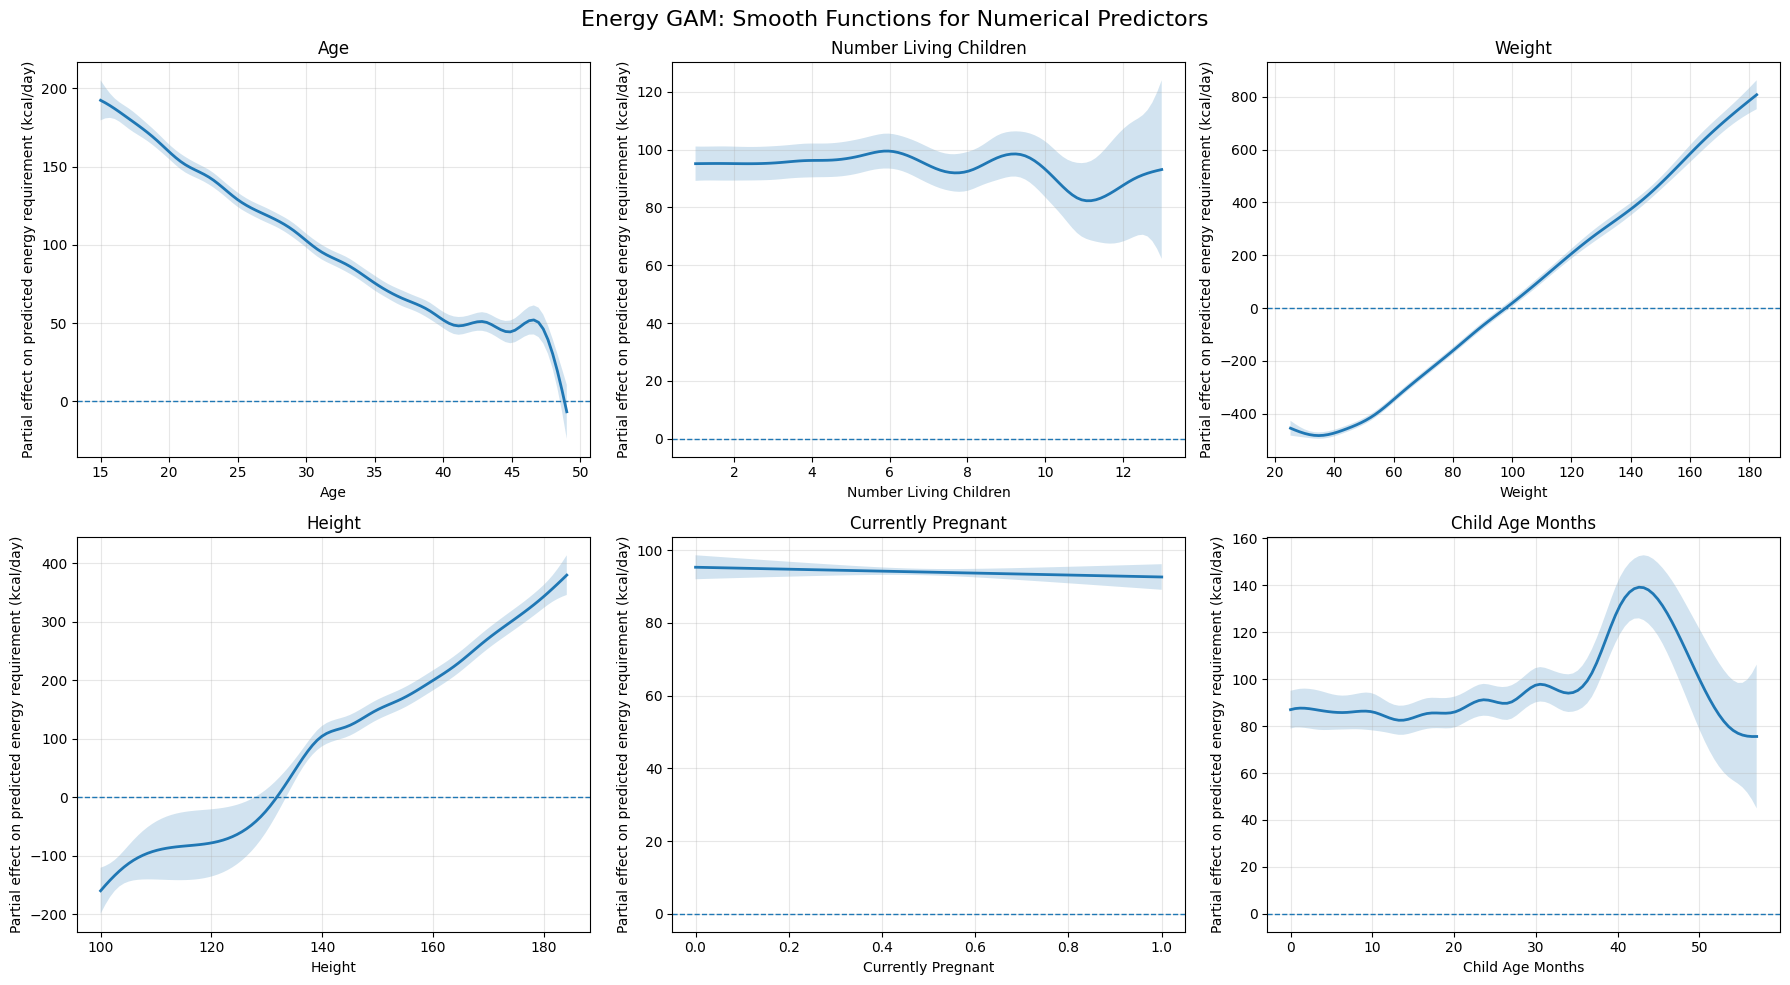


CREATING PROTEIN GAM NUMERICAL INTERPRETABILITY PLOTS...


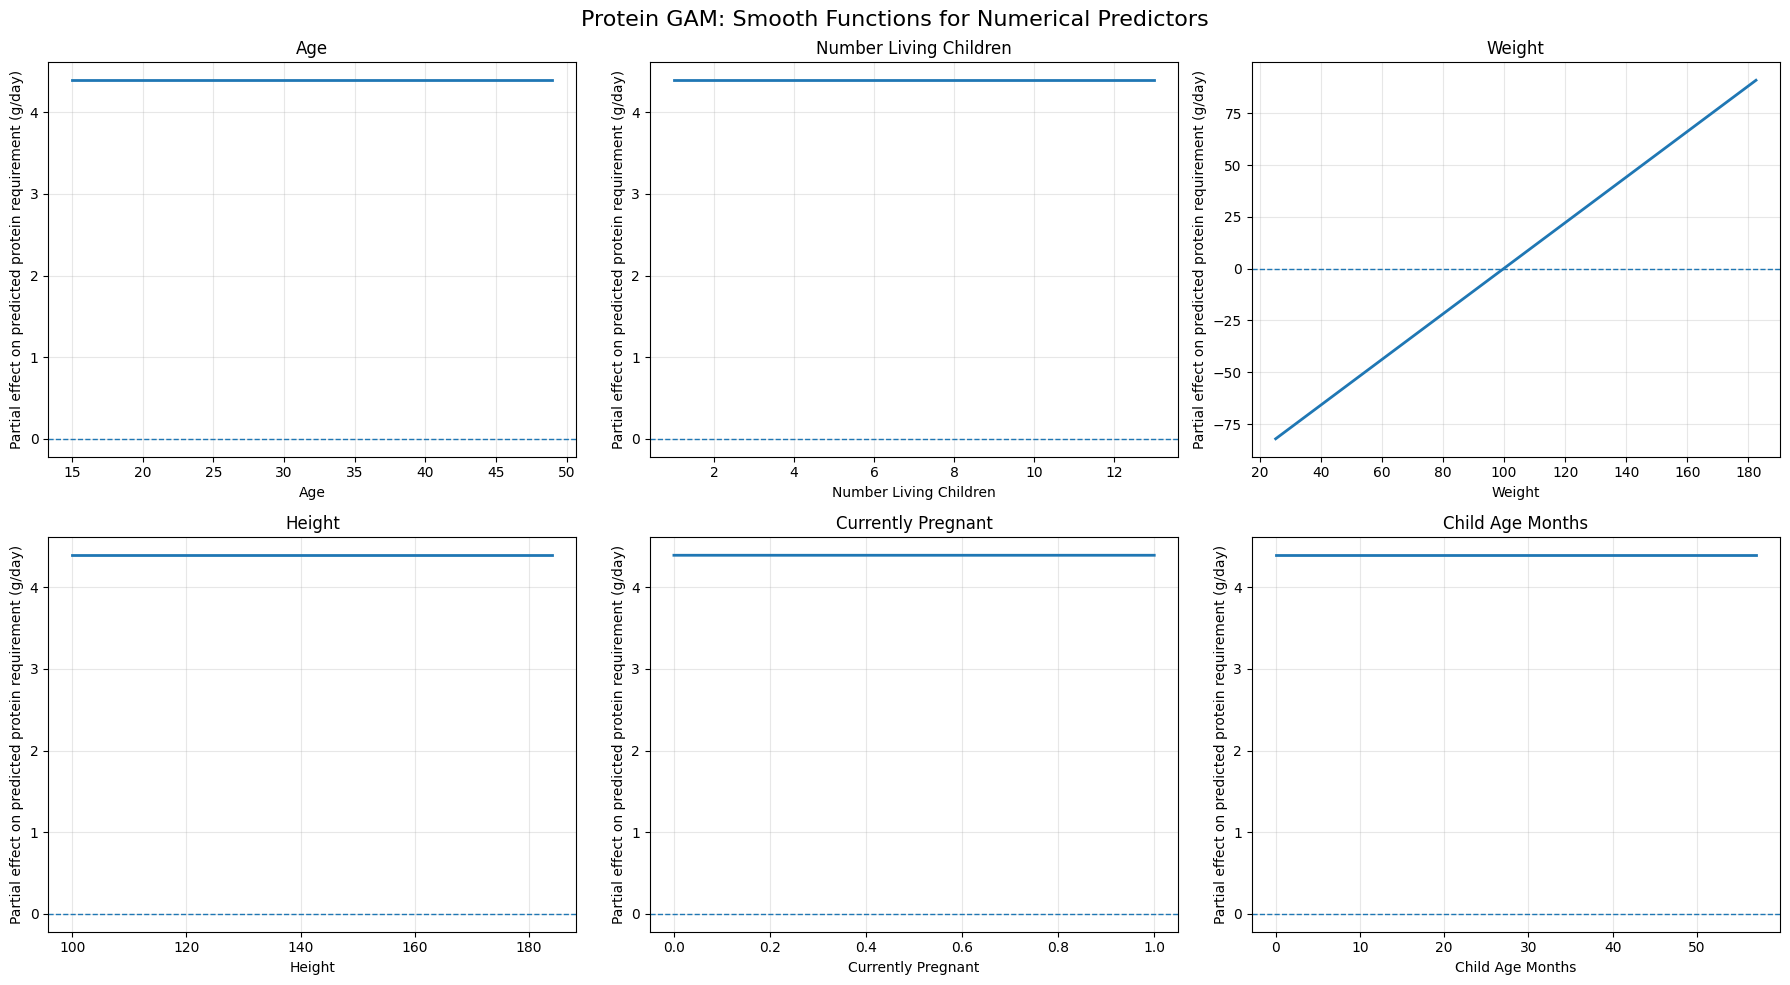


NUMERICAL INTERPRETABILITY RESULTS SAVED
gam_interpretability_plots/gam_numerical_partial_dependence_results.csv

CREATING LACTATION-STAGE EFFECT PLOTS...


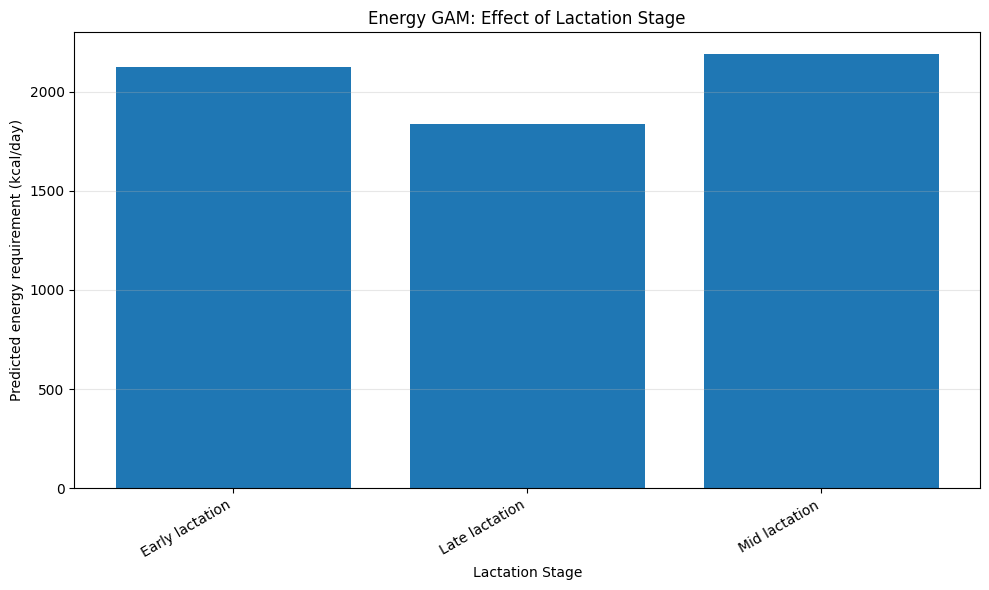

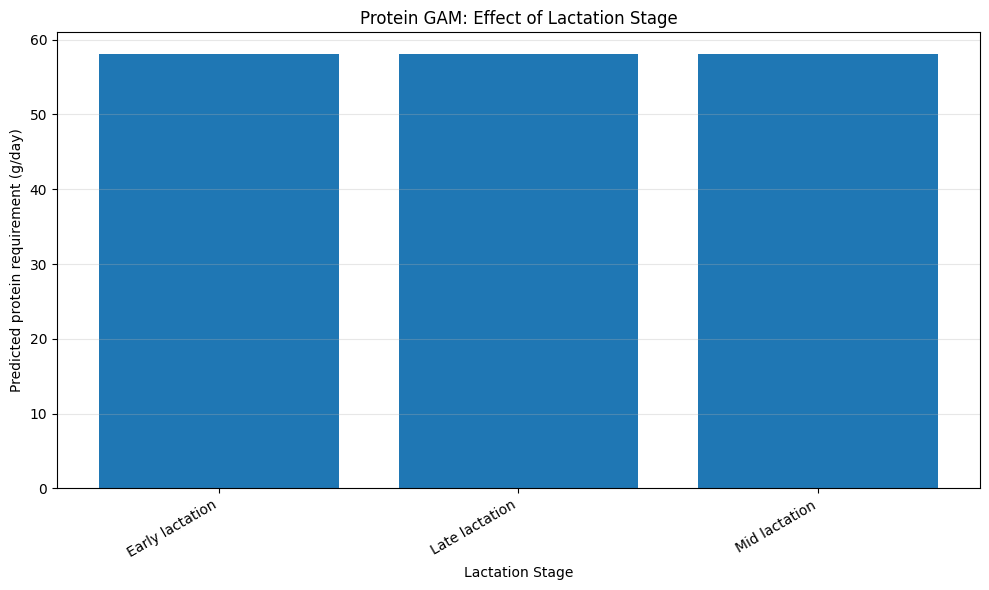


CREATING COUNTRY EFFECT PLOTS...


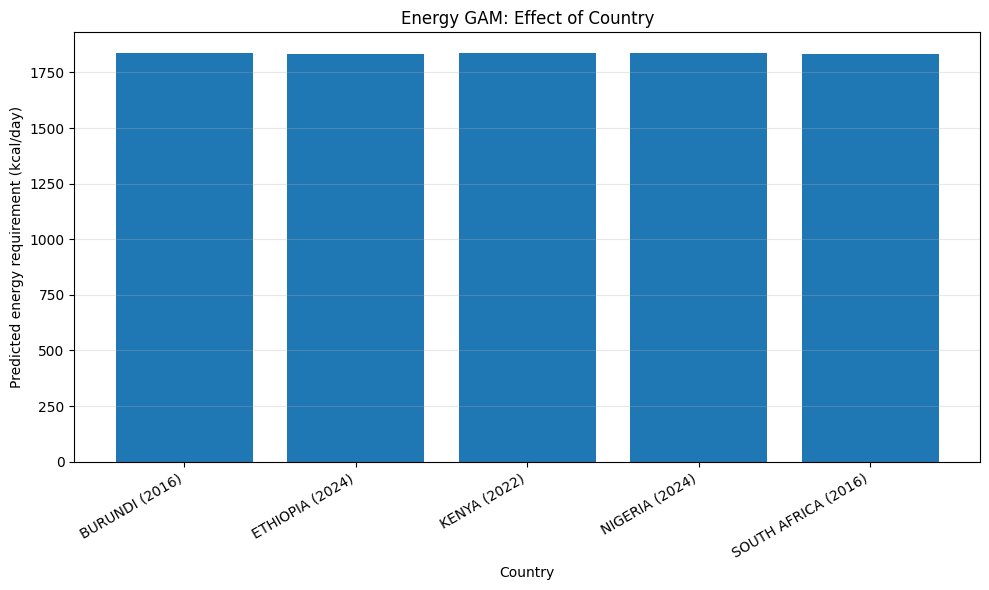

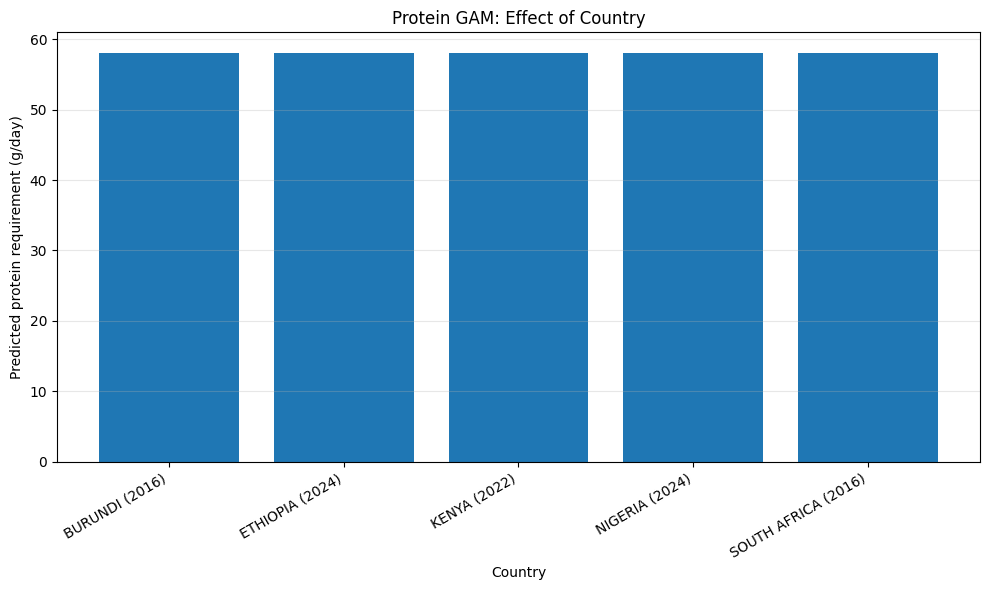


INTERPRETABILITY ANALYSIS COMPLETE

Generated files:
- gam_interpretability_plots/energy gam_country_effects.png
- gam_interpretability_plots/energy gam_lactation_stage_effects.png
- gam_interpretability_plots/energy gam_numerical_smooth_functions.png
- gam_interpretability_plots/gam_categorical_effect_results.csv
- gam_interpretability_plots/gam_numerical_partial_dependence_results.csv
- gam_interpretability_plots/protein gam_country_effects.png
- gam_interpretability_plots/protein gam_lactation_stage_effects.png
- gam_interpretability_plots/protein gam_numerical_smooth_functions.png

Energy GAM categorical effects:
        MODEL         CATEGORY            LEVEL  PREDICTED_TARGET
0  Energy GAM  LACTATION_STAGE  Early lactation       2122.348701
1  Energy GAM  LACTATION_STAGE   Late lactation       1835.429225
2  Energy GAM  LACTATION_STAGE    Mid lactation       2189.096160
        MODEL CATEGORY                LEVEL  PREDICTED_TARGET
0  Energy GAM  COUNTRY       BURUNDI (2016)     

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pygam import LinearGAM


# ================================================================
# 1. FILE PATHS
# ================================================================

TRAINING_FILE = "final_gam_training_dataset.csv"
PROTEIN_MODEL_FILE = "protein_gam_model.pkl"
ENERGY_MODEL_FILE = "energy_gam_model.pkl"

PLOT_DIR = "gam_interpretability_plots"
os.makedirs(PLOT_DIR, exist_ok=True)


# ================================================================
# 2. LOAD DATA
# ================================================================

gam_data = pd.read_csv(TRAINING_FILE)

print("DATA LOADED")
print(f"Rows: {gam_data.shape[0]}")
print(f"Columns: {gam_data.shape[1]}")


# ================================================================
# 3. LOAD SAVED GAM MODELS
# ================================================================

with open(PROTEIN_MODEL_FILE, "rb") as file:
    protein_gam = pickle.load(file)

with open(ENERGY_MODEL_FILE, "rb") as file:
    energy_gam = pickle.load(file)

print("\nMODELS LOADED")
print("Protein GAM loaded successfully.")
print("Energy GAM loaded successfully.")


# ================================================================
# 4. RECREATE THE GAM INPUT FEATURES
# ================================================================

gam_features = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS",
    "LACTATION_STAGE",
    "COUNTRY"
]

categorical_features = [
    "LACTATION_STAGE",
    "COUNTRY"
]


# Create the same one-hot encoded feature matrix used during training
X = pd.get_dummies(
    gam_data[gam_features],
    columns=categorical_features,
    drop_first=False,
    dtype=float
)

feature_names = list(X.columns)


# Convert to NumPy array
X_values = X.values


# ================================================================
# 5. DISPLAY FEATURE INFORMATION
# ================================================================

print("\nMODEL INPUT FEATURES")
print(f"Number of encoded features: {len(feature_names)}")

for i, feature in enumerate(feature_names):
    print(f"{i}: {feature}")

print("\nMODEL TERM INFORMATION")
print(f"Protein GAM terms: {len(protein_gam.terms)}")
print(f"Energy GAM terms: {len(energy_gam.terms)}")


# ================================================================
# 6. CHECK THAT THE MODEL AND DATA ARE COMPATIBLE
# ================================================================

expected_feature_count = len(feature_names)

protein_term_count = len(protein_gam.terms)
energy_term_count = len(energy_gam.terms)

if protein_term_count != expected_feature_count + 1:
    print(
        "\nWARNING: Protein GAM has a different number of terms "
        "than expected."
    )
    print(
        f"Expected approximately {expected_feature_count + 1} "
        f"terms including the intercept."
    )

if energy_term_count != expected_feature_count + 1:
    print(
        "\nWARNING: Energy GAM has a different number of terms "
        "than expected."
    )
    print(
        f"Expected approximately {expected_feature_count + 1} "
        f"terms including the intercept."
    )


# ================================================================
# 7. CREATE A BASELINE PARTICIPANT
# ================================================================

# Use median values for numerical variables
baseline = X.median().values.astype(float)


# For categorical variables, select the most common category
# instead of leaving all dummy variables at zero.

lactation_columns = [
    column
    for column in feature_names
    if column.startswith("LACTATION_STAGE_")
]

country_columns = [
    column
    for column in feature_names
    if column.startswith("COUNTRY_")
]


def set_modal_category(row, columns):
    """
    Set all dummy variables in a categorical group to zero,
    then activate the most common category.
    """
    if len(columns) == 0:
        return row

    row = row.copy()

    for column in columns:
        row[feature_names.index(column)] = 0.0

    counts = gam_data[
        column.replace("LACTATION_STAGE_", "").replace("COUNTRY_", "")
        if False
        else gam_data.columns[0]
    ]

    return row


# Create a cleaner baseline manually
baseline_row = X.median().values.astype(float)


# Set the most common lactation stage
if lactation_columns:

    lactation_counts = gam_data["LACTATION_STAGE"].value_counts()

    most_common_lactation = lactation_counts.idxmax()

    for column in lactation_columns:
        baseline_row[feature_names.index(column)] = 0.0

    lactation_column = "LACTATION_STAGE_" + str(most_common_lactation)

    if lactation_column in feature_names:
        baseline_row[feature_names.index(lactation_column)] = 1.0


# Set the most common country
if country_columns:

    country_counts = gam_data["COUNTRY"].value_counts()

    most_common_country = country_counts.idxmax()

    for column in country_columns:
        baseline_row[feature_names.index(column)] = 0.0

    country_column = "COUNTRY_" + str(most_common_country)

    if country_column in feature_names:
        baseline_row[feature_names.index(country_column)] = 1.0


print("\nBASELINE PROFILE")
print(f"Most common lactation stage: {most_common_lactation}")
print(f"Most common country: {most_common_country}")


# ================================================================
# 8. NUMERICAL FEATURES
# ================================================================

numerical_features = [
    "AGE",
    "NUMBER_LIVING_CHILDREN",
    "WEIGHT",
    "HEIGHT",
    "CURRENTLY_PREGNANT",
    "CHILD_AGE_MONTHS"
]


# ================================================================
# 9. FUNCTION TO CREATE NUMERICAL PARTIAL DEPENDENCE PLOTS
# ================================================================

def create_numeric_effect_plot(gam, model_name, target_unit):
    """
    Create partial dependence / smooth-function plots
    for all numerical GAM predictors.
    """

    results = []

    figure, axes = plt.subplots(
        2,
        3,
        figsize=(18, 10)
    )

    axes = axes.flatten()

    for plot_number, feature in enumerate(numerical_features):

        feature_index = feature_names.index(feature)

        feature_min = X[feature].min()
        feature_max = X[feature].max()

        grid_values = np.linspace(
            feature_min,
            feature_max,
            100
        )

        prediction_matrix = np.tile(
            baseline_row,
            (100, 1)
        )

        prediction_matrix[:, feature_index] = grid_values

        partial_effect, confidence_interval = gam.partial_dependence(
            term=feature_index,
            X=prediction_matrix,
            width=0.95
        )

        axes[plot_number].plot(
            grid_values,
            partial_effect,
            linewidth=2
        )

        axes[plot_number].fill_between(
            grid_values,
            confidence_interval[:, 0],
            confidence_interval[:, 1],
            alpha=0.2
        )

        axes[plot_number].axhline(
            y=0,
            linestyle="--",
            linewidth=1
        )

        axes[plot_number].set_title(
            feature.replace("_", " ").title()
        )

        axes[plot_number].set_xlabel(
            feature.replace("_", " ").title()
        )

        axes[plot_number].set_ylabel(
            f"Partial effect on predicted {target_unit}"
        )

        axes[plot_number].grid(
            alpha=0.3
        )

        for value, effect, lower, upper in zip(
            grid_values,
            partial_effect,
            confidence_interval[:, 0],
            confidence_interval[:, 1]
        ):
            results.append(
                {
                    "MODEL": model_name,
                    "FEATURE": feature,
                    "FEATURE_VALUE": value,
                    "PARTIAL_EFFECT": effect,
                    "LOWER_CI": lower,
                    "UPPER_CI": upper
                }
            )

    figure.suptitle(
        f"{model_name}: Smooth Functions for Numerical Predictors",
        fontsize=16
    )

    figure.tight_layout()

    output_file = os.path.join(
        PLOT_DIR,
        f"{model_name.lower()}_numerical_smooth_functions.png"
    )

    figure.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(figure)

    return pd.DataFrame(results)


# ================================================================
# 10. CREATE ENERGY NUMERICAL INTERPRETABILITY PLOTS
# ================================================================

print("\nCREATING ENERGY GAM NUMERICAL INTERPRETABILITY PLOTS...")

energy_numeric_results = create_numeric_effect_plot(
    energy_gam,
    "Energy GAM",
    "energy requirement (kcal/day)"
)


# ================================================================
# 11. CREATE PROTEIN NUMERICAL INTERPRETABILITY PLOTS
# ================================================================

print("\nCREATING PROTEIN GAM NUMERICAL INTERPRETABILITY PLOTS...")

protein_numeric_results = create_numeric_effect_plot(
    protein_gam,
    "Protein GAM",
    "protein requirement (g/day)"
)


# ================================================================
# 12. SAVE NUMERICAL INTERPRETABILITY RESULTS
# ================================================================

numeric_results = pd.concat(
    [
        energy_numeric_results,
        protein_numeric_results
    ],
    ignore_index=True
)

numeric_results_file = os.path.join(
    PLOT_DIR,
    "gam_numerical_partial_dependence_results.csv"
)

numeric_results.to_csv(
    numeric_results_file,
    index=False
)

print("\nNUMERICAL INTERPRETABILITY RESULTS SAVED")
print(numeric_results_file)


# ================================================================
# 13. FUNCTION FOR CATEGORICAL EFFECTS
# ================================================================

def create_categorical_effect_plot(
    gam,
    model_name,
    category_name,
    category_columns,
    target_unit
):
    """
    Compare predicted target values across categories
    while keeping numerical variables at their median values.
    """

    category_values = []

    for column in category_columns:

        category_label = column.replace(
            f"{category_name}_",
            ""
        )

        prediction_row = baseline_row.copy()

        # Turn off every category in this group
        for other_column in category_columns:
            prediction_row[
                feature_names.index(other_column)
            ] = 0.0

        # Turn on the selected category
        prediction_row[
            feature_names.index(column)
        ] = 1.0

        prediction = gam.predict(
            prediction_row.reshape(1, -1)
        )[0]

        category_values.append(
            {
                "MODEL": model_name,
                "CATEGORY": category_name,
                "LEVEL": category_label,
                "PREDICTED_TARGET": prediction
            }
        )

    category_results = pd.DataFrame(
        category_values
    )

    figure = plt.figure(
        figsize=(10, 6)
    )

    plt.bar(
        category_results["LEVEL"],
        category_results["PREDICTED_TARGET"]
    )

    plt.xlabel(
        category_name.replace("_", " ").title()
    )

    plt.ylabel(
        f"Predicted {target_unit}"
    )

    plt.title(
        f"{model_name}: Effect of {category_name.replace('_', ' ').title()}"
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    output_file = os.path.join(
        PLOT_DIR,
        f"{model_name.lower()}_{category_name.lower()}_effects.png"
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(figure)

    return category_results


# ================================================================
# 14. LACTATION-STAGE EFFECTS
# ================================================================

print("\nCREATING LACTATION-STAGE EFFECT PLOTS...")

energy_lactation_results = create_categorical_effect_plot(
    energy_gam,
    "Energy GAM",
    "LACTATION_STAGE",
    lactation_columns,
    "energy requirement (kcal/day)"
)

protein_lactation_results = create_categorical_effect_plot(
    protein_gam,
    "Protein GAM",
    "LACTATION_STAGE",
    lactation_columns,
    "protein requirement (g/day)"
)


# ================================================================
# 15. COUNTRY EFFECTS
# ================================================================

print("\nCREATING COUNTRY EFFECT PLOTS...")

energy_country_results = create_categorical_effect_plot(
    energy_gam,
    "Energy GAM",
    "COUNTRY",
    country_columns,
    "energy requirement (kcal/day)"
)

protein_country_results = create_categorical_effect_plot(
    protein_gam,
    "Protein GAM",
    "COUNTRY",
    country_columns,
    "protein requirement (g/day)"
)


# ================================================================
# 16. SAVE CATEGORICAL RESULTS
# ================================================================

categorical_results = pd.concat(
    [
        energy_lactation_results,
        protein_lactation_results,
        energy_country_results,
        protein_country_results
    ],
    ignore_index=True
)

categorical_results_file = os.path.join(
    PLOT_DIR,
    "gam_categorical_effect_results.csv"
)

categorical_results.to_csv(
    categorical_results_file,
    index=False
)


# ================================================================
# 17. DISPLAY FINAL OUTPUT SUMMARY
# ================================================================

print("\nINTERPRETABILITY ANALYSIS COMPLETE")

print("\nGenerated files:")

for filename in sorted(os.listdir(PLOT_DIR)):
    print(
        f"- {os.path.join(PLOT_DIR, filename)}"
    )

print("\nEnergy GAM categorical effects:")
print(
    energy_lactation_results
)

print(
    energy_country_results
)

print("\nProtein GAM categorical effects:")
print(
    protein_lactation_results
)

print(
    protein_country_results
)

#LP PRE-PROCESSING

*   I did this part in VS code so this just the code I had used to preprocess the Open Food Facts dataset.



In [ ]:
import importlib

# Load pandas dynamically
pd = importlib.import_module("pandas")
import logging
import os

# ----------------------------
# Logging setup
# ----------------------------
logging.basicConfig(
    filename="preprocessing_log.txt",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)

logging.info("Starting preprocessing of OpenFoodFacts dataset...")

# ----------------------------
# File and chunk settings
# ----------------------------
input_file = r"C:\en.openfoodfacts.org.products.csv"  # adjust path
output_file = "food_lp_cleaned.csv"
chunksize = 50000

# ----------------------------
# Columns to keep
# ----------------------------
useful_cols = [
    "product_name", "serving_size", "categories_tags", "labels_tags", "allergens", "image_url",
    # Macronutrients
    "energy_100g", "proteins_100g", "fat_100g", "carbohydrates_100g", "fiber_100g",
    # Micronutrients
    "calcium_100g", "iron_100g", "vitamin-a_100g", "vitamin-b12_100g",
    "vitamin-c_100g", "vitamin-d_100g",
    "vitamin-b1_100g", "vitamin-b2_100g", "vitamin-b6_100g",
    "folates_100g", "magnesium_100g",
    "zinc_100g", "sodium_100g", "selenium_100g", "iodine_100g"
]

# ----------------------------
# Cuisine mapping
# ----------------------------
cuisine_map = {
    "indian": "Indian",
    "asian": "Asian",
    "chinese": "Asian",
    "japanese": "Asian",
    "thai": "Asian",
    "korean": "Asian",
    "mediterranean": "Mediterranean",
    "greek": "Mediterranean",
    "turkish": "Mediterranean",
    "lebanese": "Middle Eastern",
    "moroccan": "African",
    "ethiopian": "African",
    "nigerian": "African",
    "italian": "European",
    "french": "European",
    "spanish": "European",
    "mexican": "Latin American",
    "brazilian": "Latin American",
    "peruvian": "Latin American",
    "american": "North American",
    "canadian": "North American"
}

def assign_cuisine(tags):
    if pd.isna(tags):
        return None
    tags_lower = tags.lower()
    for keyword, cuisine in cuisine_map.items():
        if keyword in tags_lower:
            return cuisine
    return "Other"

def assign_diet(tags):
    if pd.isna(tags):
        return "Other"
    tags_lower = tags.lower()
    if "vegan" in tags_lower:
        return "Vegan"
    elif "vegetarian" in tags_lower:
        return "Vegetarian"
    elif "lactose-free" in tags_lower:
        return "Lactose-free"
    elif "gluten-free" in tags_lower:
        return "Gluten-free"
    else:
        return "Other"

def assign_allergy(allergens):
    if pd.isna(allergens):
        return "None"
    allergens_lower = allergens.lower()
    if "nuts" in allergens_lower:
        return "Nuts"
    elif "soy" in allergens_lower or "soya" in allergens_lower:
        return "Soy"
    elif "shellfish" in allergens_lower or "crustacean" in allergens_lower:
        return "Shellfish"
    else:
        return "Other"

# ----------------------------
# Processing loop
# ----------------------------
filtered_data = []
total_rows = 0
kept_rows = 0
dropped_rows = 0
skipped_bad_lines = 0  # initialize counter

for chunk in pd.read_csv(
    input_file,
    sep="\t",
    chunksize=chunksize,
    low_memory=False,
    on_bad_lines="skip"   # skip malformed rows
):
    total_rows += len(chunk)

    # Keep only useful columns that exist in this chunk
    cols_present = [col for col in useful_cols if col in chunk.columns]
    chunk = chunk[cols_present]

    # Filter to food categories only
    if "categories_tags" in chunk.columns:
        chunk = chunk[chunk["categories_tags"].str.contains("food", na=False)]

    # Drop rows missing critical nutrients (energy + protein at minimum)
    if {"energy_100g", "proteins_100g"}.issubset(chunk.columns):
        before_drop = len(chunk)
        chunk = chunk.dropna(subset=["energy_100g", "proteins_100g"])
        dropped_rows += (before_drop - len(chunk))

    # Assign cuisine, diet, allergy
    if "categories_tags" in chunk.columns:
        chunk["cuisine"] = chunk["categories_tags"].apply(assign_cuisine)
    if "labels_tags" in chunk.columns:
        chunk["diet"] = chunk["labels_tags"].apply(assign_diet)
    if "allergens" in chunk.columns:
        chunk["allergy"] = chunk["allergens"].apply(assign_allergy)

    kept_rows += len(chunk)
    filtered_data.append(chunk)

    logging.info(f"Processed chunk: {len(chunk)} rows kept")

# ----------------------------
# Concatenate and save
# ----------------------------
df = pd.concat(filtered_data)
df.drop_duplicates(subset=["product_name"], inplace=True)

df.to_csv(output_file, index=False)

# ----------------------------
# Final log summary
# ----------------------------
logging.info(f"Total rows read: {total_rows}")
logging.info(f"Total rows kept: {kept_rows}")
logging.info(f"Total rows dropped (missing nutrients): {dropped_rows}")
logging.info(f"Malformed rows skipped: {skipped_bad_lines}")
logging.info(f"Final dataset size: {df.shape}")
logging.info(f"Output file saved: {os.path.abspath(output_file)}")

print("Preprocessing complete. See preprocessing_log.txt for details.")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\en.openfoodfacts.org.products.csv'

#LP TRAINING

#WEB INTERFACE

#MERGING FRONT-END AND BACKEND